# PCA and Kernel PCA on Structured Data

This notebook investigates:

1. Principal Component Analysis (PCA) on the Iris dataset
2. The limitations of linear PCA on nonlinear data
3. How Kernel PCA overcomes those limitations

We will analyze both the mathematical objective functions and the geometric intuition behind each method.

## Part (a): PCA on the Iris Dataset

The Iris dataset contains 150 samples with 4 features:

- Sepal length
- Sepal width
- Petal length
- Petal width

There are three classes:

- Setosa
- Versicolor
- Virginica

PCA is an **unsupervised dimensionality reduction method** that finds directions maximizing total variance in the data.

Mathematically, PCA solves:

max_w Var(w^T X)

subject to ||w|| = 1.

The solution corresponds to the eigenvectors of the covariance matrix.

In [5]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

iris = load_iris()
X = iris.data
y = iris.target

# features with larger scales would otherwise dominate the variance.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cov_matrix = np.cov(X_scaled.T)
print("Covariance Matrix:\n", cov_matrix)

# Apply PCA to reduce to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Eigenvalues correspond to variance captured along each PC
eigenvalues = pca.explained_variance_
explained_variance_ratio = pca.explained_variance_ratio_

print("\nEigenvalues:", eigenvalues)
print("Explained Variance Ratio:", explained_variance_ratio)
print("Total variance explained by 2 components:", np.sum(explained_variance_ratio))

Covariance Matrix:
 [[ 1.00671141 -0.11835884  0.87760447  0.82343066]
 [-0.11835884  1.00671141 -0.43131554 -0.36858315]
 [ 0.87760447 -0.43131554  1.00671141  0.96932762]
 [ 0.82343066 -0.36858315  0.96932762  1.00671141]]

Eigenvalues: [2.93808505 0.9201649 ]
Explained Variance Ratio: [0.72962445 0.22850762]
Total variance explained by 2 components: 0.9581320720000166


### Interpretation of Results

- The first principal component (PC1) has the largest eigenvalue.
- This means it captures the largest portion of total variance.
- In the Iris dataset, most variation comes from petal measurements.
- Therefore, PC1 aligns strongly with petal length and width.

The first two principal components usually explain around 95% of total variance,
meaning we can represent the dataset in 2D with minimal information loss.

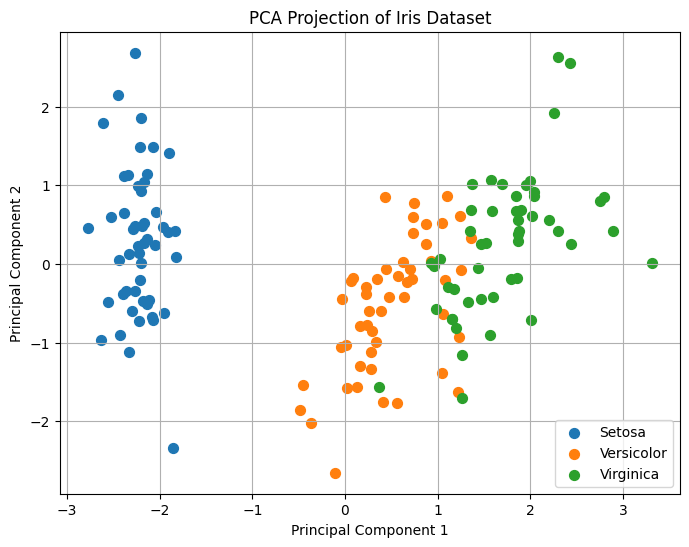

In [6]:
# Visualization of PCA projection
plt.figure(figsize=(8,6))

plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], label='Setosa', s=50)
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], label='Versicolor', s=50)
plt.scatter(X_pca[y == 2, 0], X_pca[y == 2, 1], label='Virginica', s=50)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection of Iris Dataset')
plt.legend()
plt.grid(True)
plt.show()

### Are the classes well separated?

- Setosa is clearly separated.
- Versicolor and Virginica overlap.

This is expected because PCA:

- Maximizes total variance
- Does NOT use class labels
- Does NOT optimize class separation

Thus, PCA is not guaranteed to produce optimal classification boundaries.

If classification is the goal, Linear Discriminant Analysis (LDA) is often better.

LDA maximizes:

Between-class variance / Within-class variance

Unlike PCA, LDA explicitly uses labels and tries to separate class means.

## Part (b): Nonlinear Dataset — Nested Circles

We now generate a dataset of two concentric circles.

This dataset is NOT linearly separable.

No straight line can separate the two classes.

In [7]:
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA

# Generate nonlinear dataset
X_circles, y_circles = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=42)

# standard PCA
pca_circles = PCA(n_components=2)
X_pca_circles = pca_circles.fit_transform(X_circles)

# The RBF kernel implicitly maps data into infinite-dimensional space
kpca = KernelPCA(n_components=2, kernel='rbf', gamma=10)
X_kpca = kpca.fit_transform(X_circles)

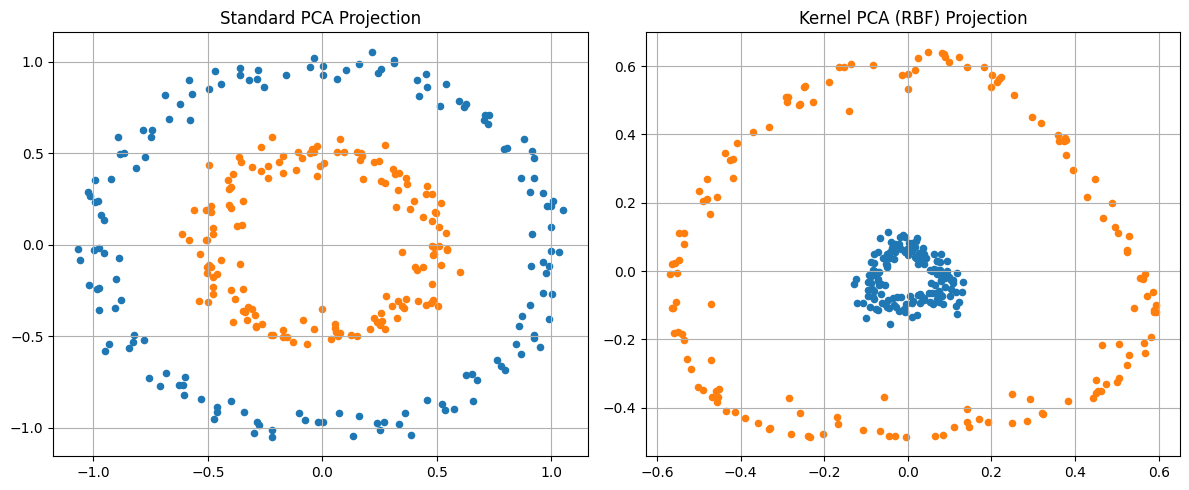

In [8]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(X_pca_circles[y_circles==0,0], X_pca_circles[y_circles==0,1], s=20)
plt.scatter(X_pca_circles[y_circles==1,0], X_pca_circles[y_circles==1,1], s=20)
plt.title('Standard PCA Projection')
plt.grid(True)

plt.subplot(1,2,2)
plt.scatter(X_kpca[y_circles==0,0], X_kpca[y_circles==0,1], s=20)
plt.scatter(X_kpca[y_circles==1,0], X_kpca[y_circles==1,1], s=20)
plt.title('Kernel PCA (RBF) Projection')
plt.grid(True)

plt.tight_layout()
plt.show()

### Why does standard PCA fail?

- PCA performs only linear projections.
- The circular structure is symmetric.
- Variance is similar in all directions.
- Therefore, PCA cannot unfold the circular geometry.

### Why does Kernel PCA succeed?

Kernel PCA applies a nonlinear feature mapping:

phi(x) → high-dimensional space

Instead of computing phi(x) explicitly, it uses the kernel trick:

K(x_i, x_j) = exp(-gamma ||x_i - x_j||^2)

This allows PCA to operate in a space where:

- The circles become linearly separable
- The nonlinear structure is captured

Thus, Kernel PCA can recover nonlinear manifolds that standard PCA cannot.